# DWC26 — History Matching & 20-Year Forecast

**Workflow stage:** Data Preparation ✅ → ML Proxy Model Training ✅ → ML Prediction ✅ → **Optimization (History Matching) → Forecast Production**

`ML_Proxy_Model.ipynb` built the proxy (4 uncertainty parameters → production curves) and the forecast method, but
stopped before the optimisation step: its deliverable was a DEMO filled with test cases 86–95. This notebook finishes
the workflow from the slides:

1. Find the parameter sets whose proxy history reproduces the **observed field** (history matching).
2. Pick the **best 10** of them.
3. Forecast each one from 2008-04-01 to 2028-01-01 and fill `09 Template Deliverable.xlsx`.

All logic lives in the `pipeline/` package (`python -m pipeline.main` runs the same thing without charts). This
notebook calls it step by step and shows the analysis behind each choice.

| Module | What it does |
|---|---|
| `pipeline/data.py` | Reads the prepared curves in `data/` (simulated cases + observed field history) |
| `pipeline/proxy.py` | The Gaussian Process proxy and decline-curve forecast from `ML_Proxy_Model.ipynb` |
| `pipeline/history_match.py` | Misfit function, global search + local polishing, selection of the 10 cases |
| `pipeline/forecast.py` | Forecast tied to the observed field, and the template writer |
| `pipeline/main.py` | Blind test, field backtest, end-to-end run |

## 1. Setup

In [1]:
import sys
import time
import warnings
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.colors import LogNorm
from scipy.stats import qmc
from sklearn.exceptions import ConvergenceWarning

ROOT = Path.cwd().parent if Path.cwd().name == 'notebook' else Path.cwd()
sys.path.insert(0, str(ROOT))

from pipeline.config import (COLORS, DELIVERABLE_PATH, FC_DATES, PARAM_COLS, SEED, TEMPLATE_PATH, TEST_CASES,
                             TRAIN_CASES, UNITS, VARS)
from pipeline.data import load_field, load_params
from pipeline.forecast import forecast, write_template
from pipeline.history_match import ACCEPT_TOL, Misfit, ParamBox, history_match, history_match_de
from pipeline.main import blind_test, field_backtest
from pipeline.proxy import CurveProxy, cum_correction, decline_forecast

warnings.filterwarnings('ignore', category=ConvergenceWarning)
ix = lambda cases: np.asarray(cases) - 1  # case number -> row index in the case-ordered arrays

# Same chart styling as ML_Proxy_Model.ipynb: recessive grid/axes, one fixed colour per entity
C = {**COLORS, 'backtest_D': '#1baf7a'}
plt.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'axes.edgecolor': '#c3c2b7',
    'axes.grid': True, 'grid.color': '#e1e0d9', 'grid.linewidth': 0.6,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.labelcolor': '#52514e', 'xtick.color': '#898781', 'ytick.color': '#898781',
    'axes.titlesize': 11, 'axes.titleweight': 'bold', 'legend.frameon': False,
    'font.size': 9.5, 'lines.linewidth': 2,
})
pd.set_option('display.width', 160)

## 2. Load the data

Read from `data/`, the same files `ML_Proxy_Model.ipynb` uses: the 100 simulated cases and the observed field
history, at the 41 quarterly dates 1998-01-01 → 2008-01-01. `Simulation_*_Consolidated.xlsx` are
`02 Field Production.xlsx` reshaped by `DWC2026.ipynb` (values identical). In them the observed history is the rows
labelled `UNKNOWN_COL_101` (the original's `RAMP_History` column, which lost its name in the reshaping).
`ML_Proxy_Model.ipynb` drops those rows because it only needs the simulations; here they are the matching target.

In [2]:
field, params = load_field(), load_params()
dates = field['dates']
corr = cum_correction(field['rate'][ix(TRAIN_CASES)], field['cum'][ix(TRAIN_CASES)], dates)

print(f'Simulated curves: {field["rate"].shape} (cases, quarters, [oil, gas, water])')
print(f'History: {dates[0].date()} → {dates[-1].date()} | Forecast: {FC_DATES[0].date()} → {FC_DATES[-1].date()} '
      f'({len(FC_DATES)} quarters)')
display(params.describe().T.round(3))

Simulated curves: (100, 41, 3) (cases, quarters, [oil, gas, water])
History: 1998-01-01 → 2008-01-01 | Forecast: 2008-04-01 → 2028-01-01 (80 quarters)


,count,mean,std,min,25%,50%,75%,max
Fault Transmissibility,100.0,0.100,0.030,0.050,0.075,0.099,0.127,0.150
Porosity Multiplier,100.0,1.148,0.204,0.801,0.977,1.145,1.348,1.494
Permeability Multiplier,100.0,5.200,2.727,0.521,2.778,5.309,7.535,9.785
Aquifer Pore Volume,100.0,125.166,42.370,53.953,89.848,125.772,159.660,199.835


## 3. Data check: observed and simulated rates use different date conventions

- **Simulated** rates are the average over the quarter that **ends** at the date.
- **Observed** rates (`UNKNOWN_COL_101`, i.e. the `Field Production` sheet) are the average over the quarter that
  **starts** at the date.

The field starts producing at 1998-10-01 in the observed data, but at 1999-01-01 in every simulation, with the
*same* rate value. Cumulatives agree in both. So the observed rates are shifted one quarter later before comparing.
`load_field()` does this; below is the evidence.

In [3]:
obs_published = np.vstack([field['obs_rate'][1:], field['obs_next']])  # as written in the Field Production sheet
best_case = 76
check = pd.DataFrame({
    'Observed oil rate (as published)': obs_published[:, 0],
    f'Case {best_case} simulated oil rate': field['rate'][best_case - 1, :, 0],
    'Observed oil rate (shifted)': field['obs_rate'][:, 0],
    'Observed oil cum': field['obs_cum'][:, 0],
    f'Case {best_case} oil cum': field['cum'][best_case - 1, :, 0],
}, index=dates.date)
display(check.iloc[2:7].round(0))

,Observed oil rate (as published),Case 76 simulated oil rate,Observed oil rate (shifted),Observed oil cum,Case 76 oil cum
1998-07-01,0.0,0.0,0.0,0.0,0.0
1998-10-01,15508.0,0.0,0.0,0.0,0.0
1999-01-01,15275.0,15508.0,15508.0,1426715.0,1426715.0
1999-04-01,15440.0,15275.0,15275.0,2801479.0,2801479.0
1999-07-01,15379.0,15440.0,15440.0,4206538.0,4206544.0


Best provided case misfit, observed rates as published: 7.455
Best provided case misfit, observed rates shifted:      0.453


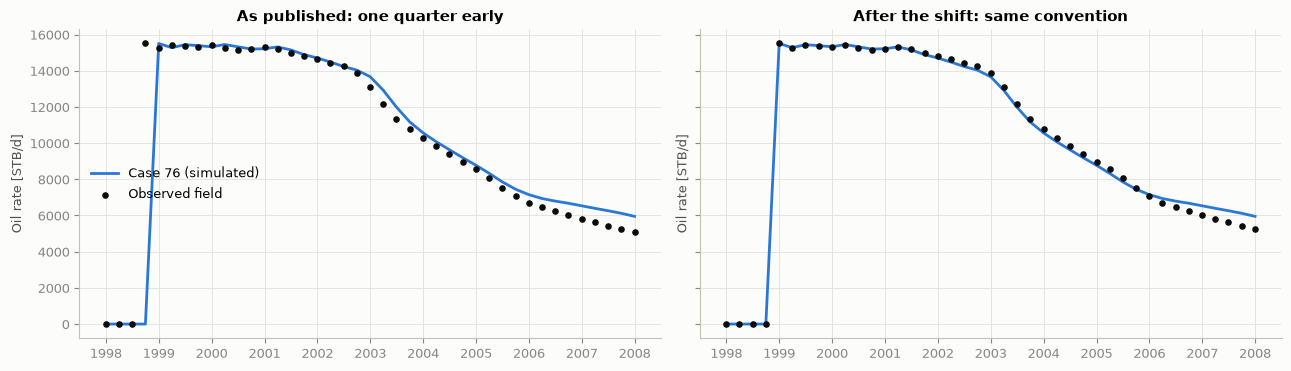

In [4]:
mis_shifted = Misfit(None, field['obs_rate'], field['obs_cum']).from_curves(field['rate'], field['cum'])
mis_published = Misfit(None, obs_published, field['obs_cum']).from_curves(field['rate'], field['cum'])
print(f'Best provided case misfit, observed rates as published: {mis_published.min():.3f}')
print(f'Best provided case misfit, observed rates shifted:      {mis_shifted.min():.3f}')

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for ax, (obs, title) in zip(axes, [(obs_published, 'As published: one quarter early'),
                                   (field['obs_rate'], 'After the shift: same convention')]):
    ax.plot(dates, field['rate'][best_case - 1, :, 0], color=C['matched'], label=f'Case {best_case} (simulated)')
    ax.scatter(dates, obs[:, 0], s=14, color=C['actual'], zorder=3, label='Observed field')
    ax.set_title(title)
    ax.set_ylabel('Oil rate [STB/d]')
axes[0].legend(loc='center left')
fig.tight_layout()
plt.show()

## 4. How good is the proxy on cases it has never seen?

The history matcher will call the proxy thousands of times instead of the simulator, so it must be accurate. Train on
cases 1–85 and predict cases 86–100. (`ML_Proxy_Model.ipynb` already chose the Gaussian Process proxy on validation
cases; this repeats the check with the code in `pipeline/proxy.py`.)

Proxy: 25 PCA components, one GP each


,2008 cum error % (mean),2008 cum error % (max),Rate RMSE % of peak
oil,0.020,0.061,0.186
gas,0.017,0.066,0.176
water,0.085,0.740,0.287


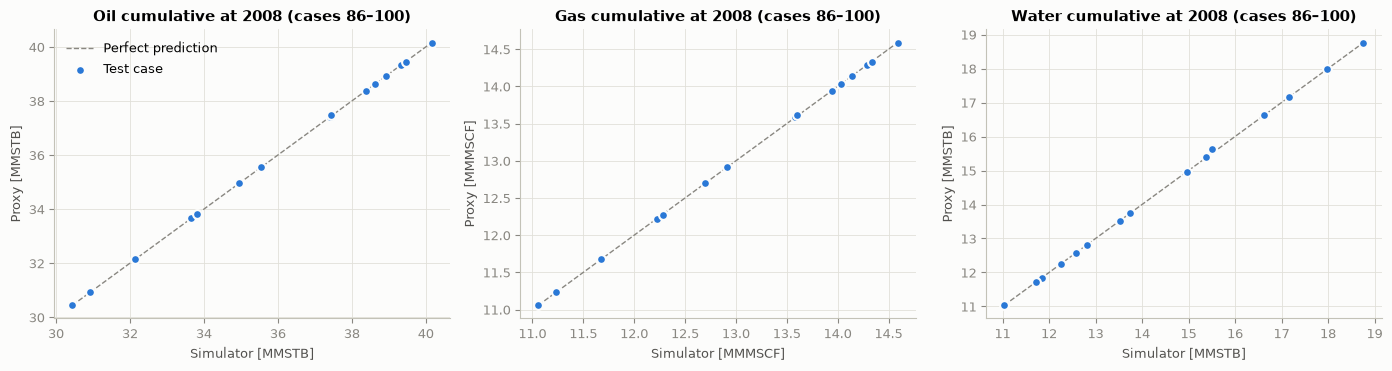

In [5]:
known = [c for c in params.index if c not in TEST_CASES]
proxy_85 = CurveProxy().fit(params.loc[known], field['rate'][ix(known)], field['cum'][ix(known)])
r_pred, c_pred = proxy_85.predict(params.loc[TEST_CASES])
r_true, c_true = field['rate'][ix(TEST_CASES)], field['cum'][ix(TEST_CASES)]

acc = pd.DataFrame({
    v: {'2008 cum error % (mean)': 100 * np.mean(np.abs(c_pred[:, -1, i] / c_true[:, -1, i] - 1)),
        '2008 cum error % (max)': 100 * np.max(np.abs(c_pred[:, -1, i] / c_true[:, -1, i] - 1)),
        'Rate RMSE % of peak': 100 * np.sqrt(np.mean((r_pred[..., i] - r_true[..., i]) ** 2)) / r_true[..., i].max()}
    for i, v in enumerate(VARS)}).T
print(f'Proxy: {proxy_85.pca.n_components_} PCA components, one GP each')
display(acc.round(3))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for v, ax in enumerate(axes):
    t, p = c_true[:, -1, v] / 1e6, c_pred[:, -1, v] / 1e6
    lo, hi = min(t.min(), p.min()), max(t.max(), p.max())
    ax.plot([lo, hi], [lo, hi], color=C['muted'], lw=1, ls='--', label='Perfect prediction')
    ax.scatter(t, p, s=40, color=C['matched'], edgecolor='#fcfcfb', linewidth=1.5, zorder=3, label='Test case')
    ax.set_title(f'{VARS[v].title()} cumulative at 2008 (cases 86–100)')
    ax.set_xlabel(f'Simulator [MM{UNITS[v]}]')
    ax.set_ylabel(f'Proxy [MM{UNITS[v]}]')
axes[0].legend(loc='upper left')
fig.tight_layout()
plt.show()

## 5. Scoring a match: the misfit

For any candidate, the misfit compares its 1998–2008 curves with the observed field on four blocks of data:
oil rate, water rate, oil cumulative and water cumulative. Each residual is divided by an assumed measurement error σ
(rates: 3 % of the peak observed rate; cumulatives: 2 % of the final observed value), squared, averaged within a
block, then averaged over the blocks.

- **Misfit = 1** means the curves are on average one σ away from the data.
- **Gas is left out**: the gas/oil ratio is ~0.36 MSCF/STB in every case and quarter, so gas adds no information.

Before optimising, score the 100 provided simulations with their *true simulated* curves:

Misfit of the 100 provided cases: best 0.453 (case 76), median 8.08, worst 78.9


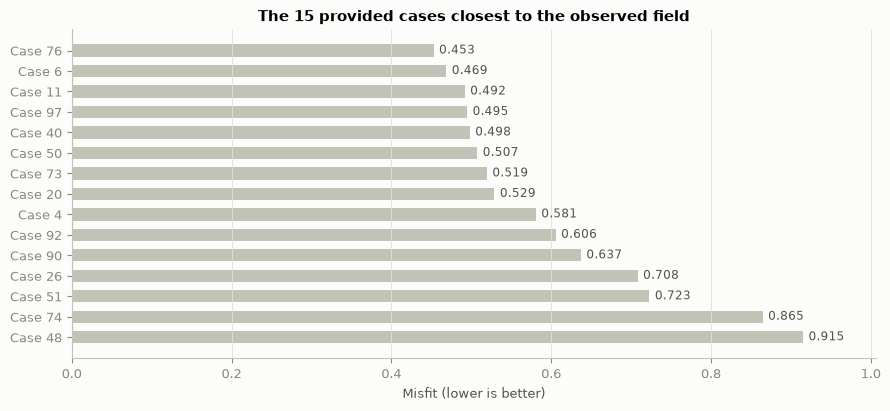

In [6]:
provided = pd.Series(mis_shifted, index=params.index, name='misfit').sort_values()
top = provided.head(15)
print(f'Misfit of the 100 provided cases: best {provided.min():.3f} (case {provided.idxmin()}), '
      f'median {provided.median():.2f}, worst {provided.max():.1f}')

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.barh([f'Case {c}' for c in top.index[::-1]], top.values[::-1], color=C['provided'], height=0.6)
for y, val in enumerate(top.values[::-1]):
    ax.annotate(f'{val:.3f}', (val, y), xytext=(4, 0), textcoords='offset points', va='center', fontsize=8.5,
                color='#52514e')
ax.set_title('The 15 provided cases closest to the observed field')
ax.set_xlabel('Misfit (lower is better)')
ax.grid(axis='y', visible=False)
ax.margins(x=0.1)
fig.tight_layout()
plt.show()

No provided case gets below ~0.45. Next we search the whole parameter space with the proxy to see if anything does better.

## 6. The misfit landscape

Train the final proxy on **all 100 cases** (the test cases were only needed for reporting accuracy, which is done) and
evaluate the misfit on 4,096 Sobol points spread over the parameter box. The box is the range covered by the 100
cases, so the proxy never extrapolates. Darker = better match.

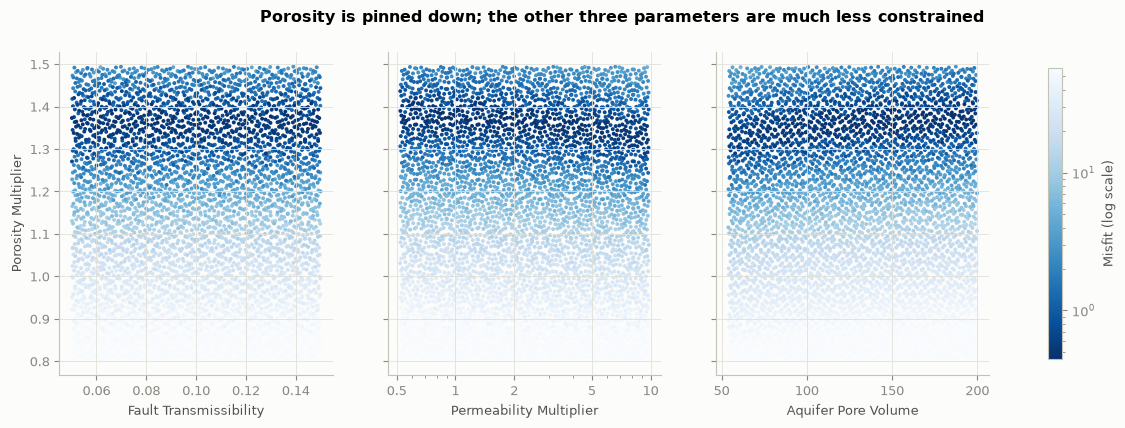

In [7]:
proxy = CurveProxy().fit(params, field['rate'], field['cum'])
misfit = Misfit(proxy, field['obs_rate'], field['obs_cum'])
box = ParamBox(params)

U = qmc.Sobol(4, scramble=True, seed=SEED).random_base2(12)
cloud = pd.DataFrame(box.to_raw(U), columns=PARAM_COLS)
cloud['misfit'] = np.concatenate([misfit(chunk) for chunk in np.array_split(cloud[PARAM_COLS].to_numpy(), 4)])
cloud = cloud.sort_values('misfit', ascending=False)  # draw best points last, on top

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
norm = LogNorm(cloud['misfit'].min(), cloud['misfit'].quantile(0.9))
for ax, p in zip(axes, ['Fault Transmissibility', 'Permeability Multiplier', 'Aquifer Pore Volume']):
    sc = ax.scatter(cloud[p], cloud['Porosity Multiplier'], c=cloud['misfit'], cmap='Blues_r', norm=norm, s=8,
                    linewidth=0)
    ax.set_xlabel(p)
    if p == 'Permeability Multiplier':
        ax.set_xscale('log')
        ax.set_xticks([0.5, 1, 2, 5, 10], ['0.5', '1', '2', '5', '10'])
axes[0].set_ylabel('Porosity Multiplier')
fig.colorbar(sc, ax=axes, label='Misfit (log scale)', shrink=0.9)
fig.suptitle('Porosity is pinned down; the other three parameters are much less constrained', fontweight='bold')
plt.show()

The good region is a thin horizontal band: **porosity is tightly constrained** by the history, while fault
transmissibility is almost free. That shapes how the 10 deliverable cases are chosen (next section).

## 7. History matching (the optimisation step)

`history_match()` does three things:

1. **Global search:** 8,192 Sobol points over the parameter box.
2. **Local polishing:** L-BFGS-B from the 40 best distinct starting points.
3. **Selection:** every point within 10 % of the best misfit (`ACCEPT_TOL`) counts as an *acceptable match*. The misfit
   has a floor (~0.44) that nothing gets below, so differences of a few percent are not meaningful. From the acceptable
   matches, 10 are picked to be **as different from each other as possible** (starting from the best match). The
   forecasts then show the remaining uncertainty instead of ten copies of one answer.

In [8]:
selected, accepted = history_match(misfit, box)
selected.index = [f'Case {k + 1}' for k in range(len(selected))]
print(f'Best provided simulation: case {provided.idxmin()} (misfit {provided.min():.3f})')
print(f'Best match found:         misfit {selected["misfit"].iloc[0]:.3f}')
print(f'Acceptable matches (≤ {1 + ACCEPT_TOL:.2f} × best): {len(accepted)}')
display(selected.round(4))

Best provided simulation: case 76 (misfit 0.453)
Best match found:         misfit 0.442
Acceptable matches (≤ 1.10 × best): 201


,misfit,Fault Transmissibility,Porosity Multiplier,Permeability Multiplier,Aquifer Pore Volume
Case 1,0.4422,0.0961,1.3833,0.9441,182.2518
Case 2,0.4477,0.1428,1.3838,0.5640,164.4180
Case 3,0.4610,0.1155,1.3681,3.1129,189.1728
Case 4,0.4618,0.0519,1.3644,1.4531,142.3008
Case 5,0.4646,0.1476,1.3652,2.1137,125.6024
Case 6,0.4685,0.0581,1.4018,0.6655,195.9534
Case 7,0.4733,0.1035,1.3493,3.0269,115.6202
Case 8,0.4753,0.0535,1.3623,4.5588,193.4332
Case 9,0.4851,0.0930,1.3711,0.7843,104.7713
Case 10,0.4853,0.0623,1.3438,4.7030,95.3407


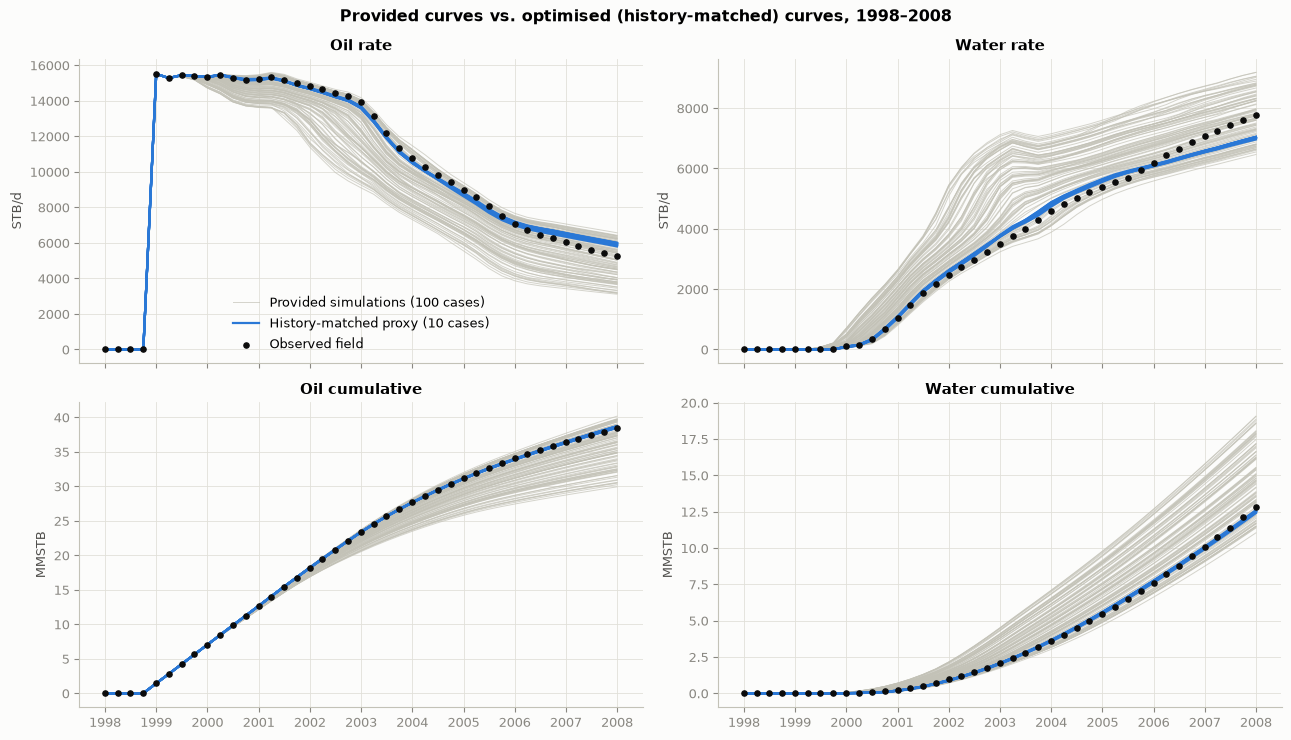

In [9]:
theta = selected[PARAM_COLS].to_numpy()
r_hm, c_hm = proxy.predict(theta)

panels = [('rate', 0, 'Oil rate', 'STB/d'), ('rate', 2, 'Water rate', 'STB/d'),
          ('cum', 0, 'Oil cumulative', 'MMSTB'), ('cum', 2, 'Water cumulative', 'MMSTB')]
matched = {'rate': r_hm, 'cum': c_hm}
fig, axes = plt.subplots(2, 2, figsize=(13, 7.5), sharex=True)
for ax, (kind, v, title, unit) in zip(axes.flat, panels):
    s = 1e6 if kind == 'cum' else 1
    obs = field['obs_rate'] if kind == 'rate' else field['obs_cum']
    for j, curve in enumerate(field[kind][:, :, v]):
        ax.plot(dates, curve / s, color=C['provided'], lw=0.7, alpha=0.7,
                label='Provided simulations (100 cases)' if j == 0 else None)
    for j, curve in enumerate(matched[kind][:, :, v]):
        ax.plot(dates, curve / s, color=C['matched'], lw=1.6,
                label='History-matched proxy (10 cases)' if j == 0 else None)
    ax.scatter(dates, obs[:, v] / s, s=14, color=C['actual'], zorder=3, label='Observed field')
    ax.set_title(title)
    ax.set_ylabel(unit)
axes[0, 0].legend(loc='lower center')
fig.suptitle('Provided curves vs. optimised (history-matched) curves, 1998–2008', fontweight='bold')
fig.tight_layout()
plt.show()

The matched curves sit on the observed points through the whole history. The visible gap is **late-time water**:
the field ends 2008 at ~60 % water cut, while the best match reaches ~54 %, and none of the 100 provided cases does
better. That gap is structural (the simulation model cannot reproduce it inside the given parameter ranges) and is
dealt with in the forecast (Section 10).

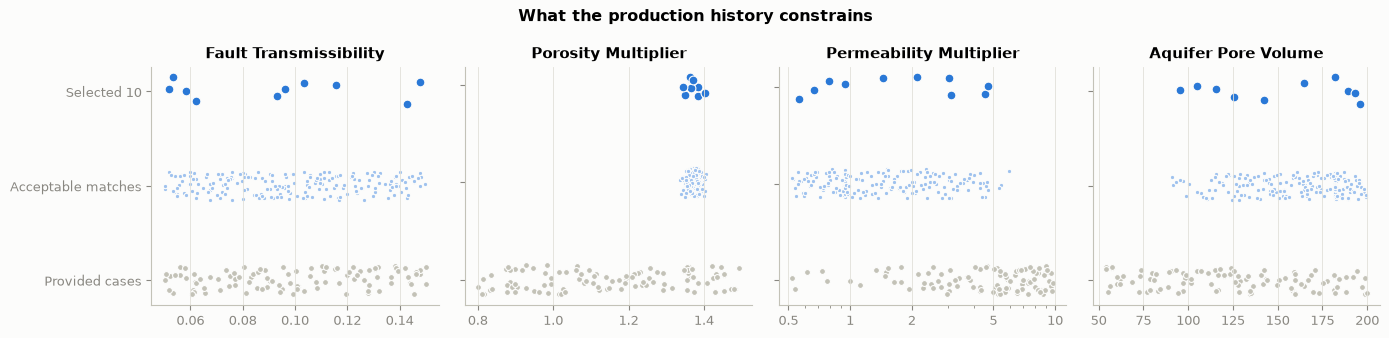

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.4))
rng = np.random.default_rng(0)
groups = [('Provided cases', params, C['provided'], 18), ('Acceptable matches', accepted, '#9fc2ee', 10),
          ('Selected 10', selected, C['matched'], 40)]
for ax, p in zip(axes, PARAM_COLS):
    for y, (_, df, color, size) in enumerate(groups):
        ax.scatter(df[p], y + rng.uniform(-0.15, 0.15, len(df)), s=size, color=color, edgecolor='#fcfcfb',
                   linewidth=0.8)
    ax.set_yticks(range(len(groups)), [g[0] for g in groups] if p == PARAM_COLS[0] else [])
    ax.set_title(p)
    ax.grid(axis='y', visible=False)
    if p == 'Permeability Multiplier':
        ax.set_xscale('log')
        ax.set_xticks([0.5, 1, 2, 5, 10], ['0.5', '1', '2', '5', '10'])
fig.suptitle('What the production history constrains', fontweight='bold')
fig.tight_layout()
plt.show()

## 7b. Optimizer check: Differential Evolution

Section 7 searches with **Sobol screening + L-BFGS-B polishing**. Would a different optimizer find a better match, or
the same match more cheaply? The alternative tested here is **Differential Evolution (DE)**, `history_match_de()`:

- Start with a population of 60 random parameter sets.
- Each generation, every member proposes a trial: take another member and add the scaled *difference* between two
  more members, then mix it with the parent. The trial replaces its parent only if its misfit is lower.
- The population drifts towards the good region and shrinks onto the best match. A final L-BFGS-B step polishes it.
- DE needs no gradients and handles several valleys well, and it is a standard choice for history matching.

Both methods get the same misfit, parameter box and selection rule (acceptable = within 10 % of the best, then 10
spread-out cases). Each runs with 3 random seeds. Every parameter set an optimizer asks the proxy about is counted, so
the comparison covers both **quality** (best misfit) and **cost** (proxy evaluations, time). (~2 minutes)

In [11]:
class CountedMisfit:
    """Wraps a Misfit and records every parameter set the optimizer asks the proxy about, in order."""

    def __init__(self, misfit):
        self.misfit, self.raw, self.f = misfit, [], []

    def __call__(self, raw):
        f = self.misfit(raw)
        self.raw.append(np.atleast_2d(raw))
        self.f.append(f)
        return f

    def points(self):
        return np.vstack(self.raw), np.concatenate(self.f)


METHODS = {'Sobol + L-BFGS-B': history_match, 'Differential Evolution': history_match_de}
SEEDS = [SEED, 1, 2]
runs = []
for method, search in METHODS.items():
    for seed in SEEDS:
        counted = CountedMisfit(misfit)
        t0 = time.perf_counter()
        sel, acc = search(counted, box, seed=seed)
        runs.append({'method': method, 'seed': seed, 'seconds': time.perf_counter() - t0, 'counted': counted,
                     'selected': sel, 'accepted': acc})

opt_table = pd.DataFrame([{'method': r['method'], 'seed': r['seed'], 'best misfit': r['selected']['misfit'].iloc[0],
                           'proxy evaluations': len(r['counted'].points()[1]), 'seconds': r['seconds'],
                           **r['selected'][PARAM_COLS].iloc[0].to_dict()} for r in runs])
display(opt_table.round({'best misfit': 4, 'seconds': 1, **{p: 3 for p in PARAM_COLS}}))

,method,seed,best misfit,proxy evaluations,seconds,Fault Transmissibility,Porosity Multiplier,Permeability Multiplier,Aquifer Pore Volume
0,Sobol + L-BFGS-B,42,0.4422,14657,30.8,0.096,1.383,0.944,182.252
1,Sobol + L-BFGS-B,1,0.4422,15367,36.7,0.096,1.383,0.941,182.253
2,Sobol + L-BFGS-B,2,0.4422,15002,31.4,0.096,1.383,0.944,182.275
3,Differential Evolution,42,0.4422,3220,0.8,0.095,1.383,0.944,182.266
4,Differential Evolution,1,0.4422,3345,0.7,0.095,1.383,0.944,182.264
5,Differential Evolution,2,0.4422,3260,0.5,0.095,1.383,0.944,182.265


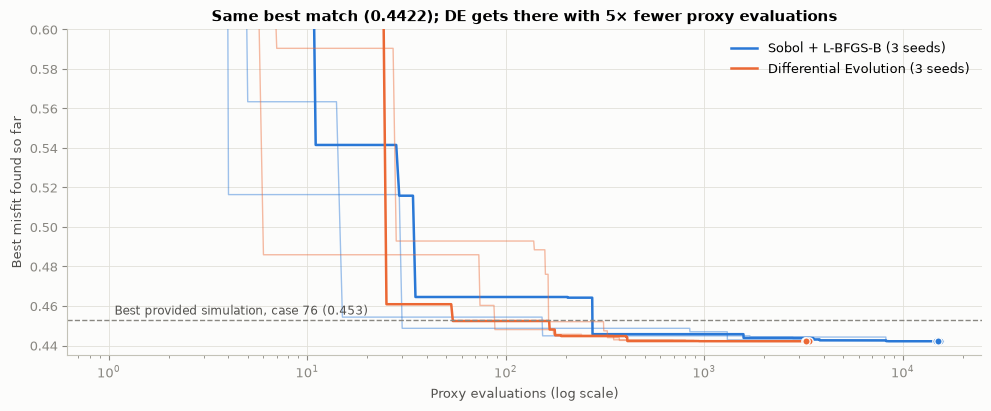

In [12]:
method_color = {'Sobol + L-BFGS-B': C['matched'], 'Differential Evolution': C['alt']}
cost = opt_table.groupby('method', sort=False)['proxy evaluations'].mean()

fig, ax = plt.subplots(figsize=(10, 4.2))
for r in runs:
    best_so_far = np.minimum.accumulate(r['counted'].points()[1])
    first = r['seed'] == SEEDS[0]
    color = method_color[r['method']]
    ax.plot(np.arange(1, len(best_so_far) + 1), best_so_far, color=color, lw=1.8 if first else 1,
            alpha=1 if first else 0.45, label=f'{r["method"]} (3 seeds)' if first else None)
    ax.scatter(len(best_so_far), best_so_far[-1], s=28, color=color, edgecolor='#fcfcfb', linewidth=1, zorder=3)
ax.axhline(provided.min(), color=C['muted'], lw=1, ls='--')
ax.annotate(f'Best provided simulation, case {provided.idxmin()} ({provided.min():.3f})', (1, provided.min()),
            xytext=(4, 4), textcoords='offset points', fontsize=8.5, color='#52514e')
ax.set_xscale('log')
ax.set_ylim(0.435, 0.6)
ax.set_xlabel('Proxy evaluations (log scale)')
ax.set_ylabel('Best misfit found so far')
ax.set_title(f'Same best match ({opt_table["best misfit"].min():.4f}); DE gets there with '
             f'{cost.iloc[0] / cost.iloc[1]:.0f}× fewer proxy evaluations')
ax.legend(loc='upper right')
fig.tight_layout()
plt.show()

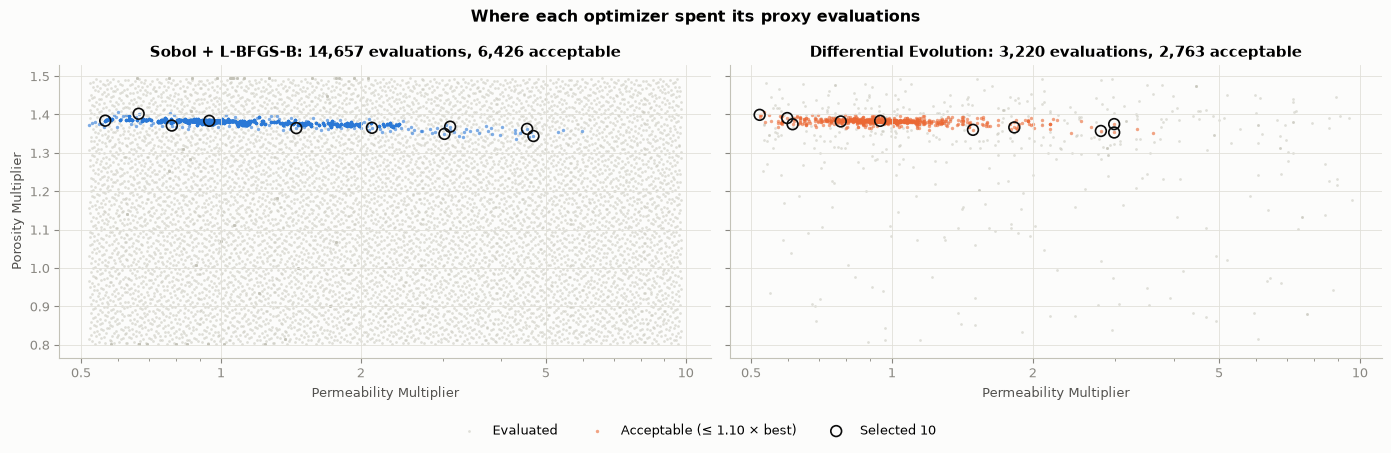

Spread of the selected 10 along each parameter (fraction of the search range):


,Sobol + L-BFGS-B,Differential Evolution
Fault Transmissibility,0.96,0.94
Porosity Multiplier,0.08,0.07
Permeability Multiplier,0.72,0.59
Aquifer Pore Volume,0.69,0.68


In [13]:
main_runs = {r['method']: r for r in runs if r['seed'] == SEEDS[0]}

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4), sharey=True)
for ax, (method, r) in zip(axes, main_runs.items()):
    raw, f = r['counted'].points()
    ok = f <= f.min() * (1 + ACCEPT_TOL)
    ax.scatter(raw[~ok, 2], raw[~ok, 1], s=4, color=C['provided'], alpha=0.5, linewidth=0, label='Evaluated')
    ax.scatter(raw[ok, 2], raw[ok, 1], s=6, color=method_color[method], alpha=0.6, linewidth=0,
               label='Acceptable (≤ 1.10 × best)')
    sel = r['selected']
    ax.scatter(sel['Permeability Multiplier'], sel['Porosity Multiplier'], s=60, facecolor='none',
               edgecolor=C['actual'], linewidth=1.2, zorder=3, label='Selected 10')
    ax.set_title(f'{method}: {len(f):,} evaluations, {ok.sum():,} acceptable')
    ax.set_xscale('log')
    ax.set_xticks([0.5, 1, 2, 5, 10], ['0.5', '1', '2', '5', '10'])
    ax.set_xlabel('Permeability Multiplier')
axes[0].set_ylabel('Porosity Multiplier')
fig.legend(*axes[1].get_legend_handles_labels(), loc='lower center', ncol=3, bbox_to_anchor=(0.5, -0.02))
fig.suptitle('Where each optimizer spent its proxy evaluations', fontweight='bold')
fig.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()

spread = pd.DataFrame({m: np.ptp(box.to_unit(r['selected'][PARAM_COLS].to_numpy()), axis=0)
                       for m, r in main_runs.items()}, index=PARAM_COLS)
print('Spread of the selected 10 along each parameter (fraction of the search range):')
display(spread.round(2))

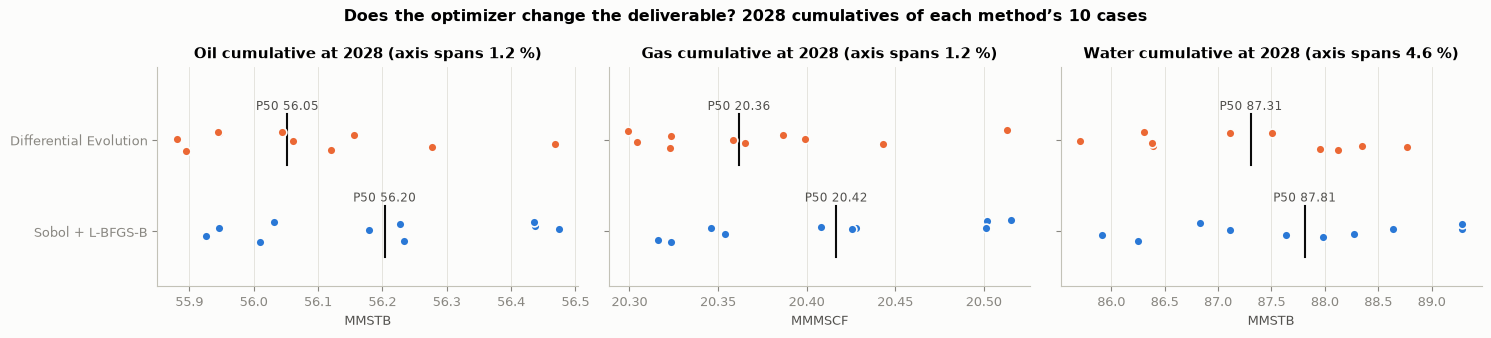

oil 2028 [MMSTB]  gas 2028 [MMMSCF]  water 2028 [MMSTB]
Sobol + L-BFGS-B       P10             55.94              20.32               86.22
                       P50             56.20              20.42               87.81
                       P90             56.44              20.50               89.29
Differential Evolution P10             55.89              20.30               86.24
                       P50             56.05              20.36               87.31
                       P90             56.30              20.45               88.39

In [14]:
cum_2028 = {m: forecast(proxy, r['selected'][PARAM_COLS].to_numpy(), dates, field['obs_rate'], field['obs_cum'], corr,
                        anchor=True)['cum'][:, -1] / 1e6
            for m, r in main_runs.items()}

fig, axes = plt.subplots(1, 3, figsize=(15, 3.4))
rng = np.random.default_rng(0)
for v, ax in enumerate(axes):
    for y, (method, cum) in enumerate(cum_2028.items()):
        ax.scatter(cum[:, v], y + rng.uniform(-0.12, 0.12, len(cum)), s=40, color=method_color[method],
                   edgecolor='#fcfcfb', linewidth=1.2, zorder=3)
        med = np.median(cum[:, v])
        ax.plot([med, med], [y - 0.28, y + 0.28], color=C['actual'], lw=1.5)
        ax.annotate(f'P50 {med:.2f}', (med, y + 0.28), xytext=(0, 3), textcoords='offset points', ha='center',
                    fontsize=8.5, color='#52514e')
    ax.set_yticks(range(len(cum_2028)), list(cum_2028) if v == 0 else [])
    ax.set_ylim(-0.6, len(cum_2028) - 0.2)
    ax.grid(axis='y', visible=False)
    lo, hi = ax.get_xlim()
    ax.set_title(f'{VARS[v].title()} cumulative at 2028 (axis spans {100 * (hi - lo) / lo:.1f} %)')
    ax.set_xlabel(f'MM{UNITS[v]}')
fig.suptitle('Does the optimizer change the deliverable? 2028 cumulatives of each method’s 10 cases',
             fontweight='bold')
fig.tight_layout()
plt.show()

pct = pd.concat({m: pd.DataFrame(np.percentile(c, [10, 50, 90], axis=0), index=['P10', 'P50', 'P90'],
                                 columns=[f'{v} 2028 [MM{u}]' for v, u in zip(VARS, UNITS)])
                 for m, c in cum_2028.items()})
display(pct.round(2))

**What the comparison shows**

- **Same answer.** All 6 runs (both methods, 3 seeds each) end at the same best match: misfit 0.4422 with the same
  parameters (porosity 1.383, permeability 0.94, aquifer 182). So the optimum is robust, and the original search was
  already finding the global best. Changing the optimizer does not improve the match.
- **DE is much cheaper.** About 3,300 proxy evaluations and ~1 s, against ~15,000 evaluations and ~30–40 s.
  DE scores a whole generation in one proxy call, while L-BFGS-B polishes 40 starts one point at a time.
- **DE explores the edges less.** 86 % of DE's evaluations land in the acceptable band (it homes in quickly), but it
  rarely visits the high-permeability end. Its 10 selected cases cover 59 % of the permeability range, against 72 %
  for Sobol + L-BFGS-B, which scans the whole box evenly first.
- **The deliverable barely moves.** The 2028 P50 differs by 0.15 MMSTB oil (0.3 %) and 0.5 MMSTB water (0.6 %). DE's
  P10–P90 spread is narrower (water 2.2 vs 3.1 MMSTB). That is because it explored less, not because the answer is
  more certain.

**Decision:** keep **Sobol + L-BFGS-B** for the deliverable. With an instant proxy, 30 s is not a real cost, and the
even scan maps the acceptable region more completely, which gives a more honest uncertainty range. DE is the better
tool when each evaluation is expensive (a slower proxy, or the real simulator), or inside repeated loops such as the
blind test and backtests below.

## 8. Blind test: can the matcher find a known answer?

For each test case 86–100, pretend its simulated history is the "observed field", run the history matcher with a proxy
trained only on cases 1–85, and compare the parameters it finds with the true ones. The 2028 forecast from the found
parameters is also compared with the forecast from the true parameters. (~1 minute)

,mean,max
misfit,0.00,0.01
Fault Transmissibility error % of range,40.78,94.67
Porosity Multiplier error % of range,0.77,1.84
Permeability Multiplier error % of range,9.34,45.77
Aquifer Pore Volume error % of range,9.72,28.60
oil cum 2028 diff %,-0.51,1.58
gas cum 2028 diff %,-0.51,1.59
water cum 2028 diff %,0.45,5.44


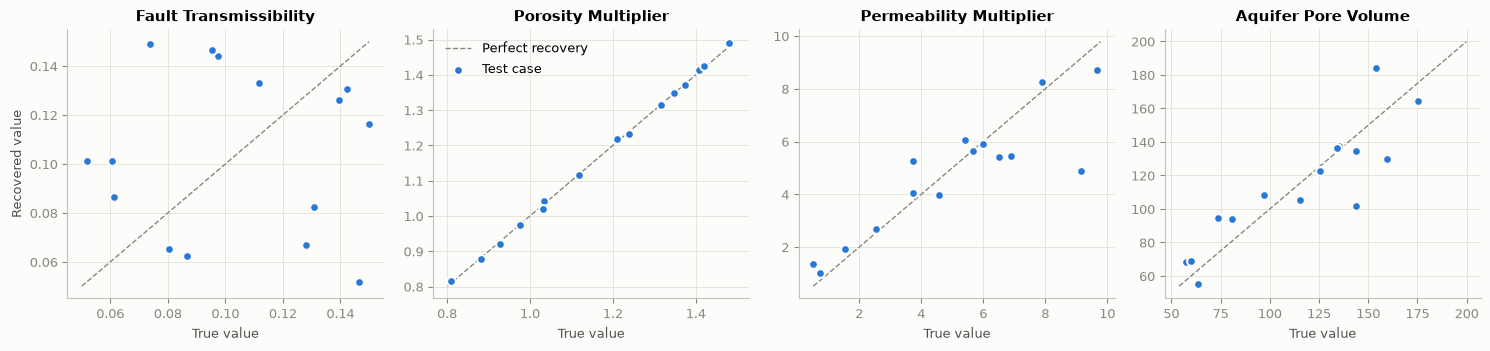

In [15]:
blind = blind_test(field, params, corr)
display(blind.filter(regex='misfit|%').describe().loc[['mean', 'max']].round(2).T)

fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, p in zip(axes, PARAM_COLS):
    t, r = blind[f'true {p}'], blind[f'recovered {p}']
    lo, hi = params[p].min(), params[p].max()
    ax.plot([lo, hi], [lo, hi], color=C['muted'], lw=1, ls='--', label='Perfect recovery')
    ax.scatter(t, r, s=40, color=C['matched'], edgecolor='#fcfcfb', linewidth=1.5, zorder=3, label='Test case')
    ax.set_title(p)
    ax.set_xlabel('True value')
    ax.set_ylabel('Recovered value' if p == PARAM_COLS[0] else '')
axes[1].legend(loc='upper left')  # empty corner
fig.tight_layout()
plt.show()

Porosity is recovered almost exactly, and the 2028 forecast from the recovered parameters lands within ~0.5 % of the
forecast from the true ones on average. Fault transmissibility is scattered: the history simply doesn't contain
enough information about it, which matches the landscape in Section 6. The forecast doesn't depend on it much either.

## 9. Field backtest: which forecast method works on the *real* field?

There is no data after 2008, so the forecast method is chosen on the real field's own history. Pretend it is an
earlier date, history-match only the data up to then, forecast the held-out quarters, and compare with what the field
actually did. Three methods:

| Method | Idea |
|---|---|
| **A: matched model** | `ML_Proxy_Model.ipynb`'s Approach A on the matched proxy history (decline curves) |
| **A+: matched model, anchored** | Same decline *shape*, but the forecast starts from the last observed rate |
| **D: decline on observed only** | Decline curves fitted to the observed data, ignoring the reservoir model |

(~1–2 minutes)

In [16]:
backtest = field_backtest(field, params, corr)
display(backtest.round(2))
bt_mean = backtest.groupby('method', sort=False).mean(numeric_only=True).drop(columns='quarters ahead')
display(bt_mean.round(2))

,cutoff,quarters ahead,method,oil rate MAPE %,oil Δcum error %,water rate MAPE %,water Δcum error %
0,2005-01-01,12,A: matched model,2.35,2.32,7.12,7.39
1,2005-01-01,12,"A+: matched model, anchored",3.07,3.68,8.51,9.49
2,2005-01-01,12,D: decline on observed only,4.23,4.91,8.76,9.76
3,2006-01-01,8,A: matched model,0.95,1.65,15.73,16.44
4,2006-01-01,8,"A+: matched model, anchored",1.61,0.73,12.82,13.58
5,2006-01-01,8,D: decline on observed only,9.58,8.52,6.38,6.96
6,2006-07-01,6,A: matched model,7.27,7.95,12.16,12.65
7,2006-07-01,6,"A+: matched model, anchored",1.18,1.83,6.57,7.07
8,2006-07-01,6,D: decline on observed only,3.65,2.90,3.68,4.15


,oil rate MAPE %,oil Δcum error %,water rate MAPE %,water Δcum error %
method,,,,
A: matched model,3.52,3.97,11.67,12.16
"A+: matched model, anchored",1.95,2.08,9.30,10.04
D: decline on observed only,5.82,5.44,6.28,6.96


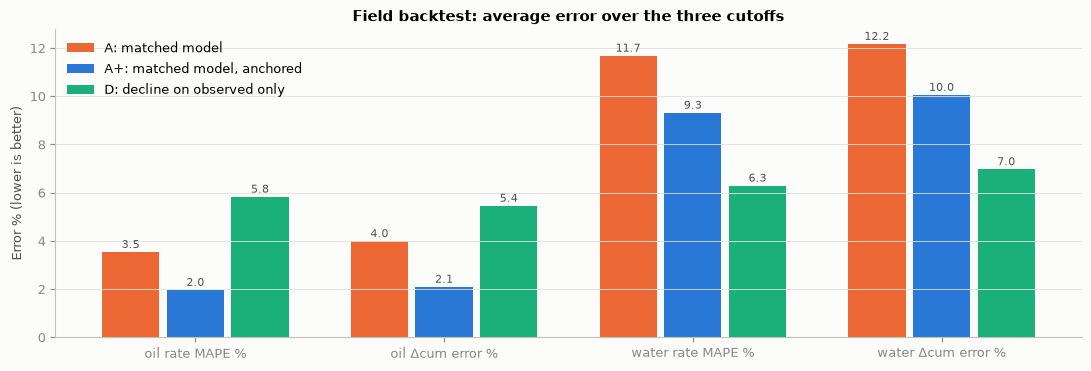

In [17]:
method_colors = {'A: matched model': C['alt'], 'A+: matched model, anchored': C['matched'],
                 'D: decline on observed only': C['backtest_D']}
metrics = list(bt_mean.columns)
fig, ax = plt.subplots(figsize=(11, 3.8))
width = 0.26
for k, (method, row) in enumerate(bt_mean.iterrows()):
    xs = np.arange(len(metrics)) + (k - 1) * width
    ax.bar(xs, row.values, width=width - 0.03, color=method_colors[method], label=method)
    for x, val in zip(xs, row.values):
        ax.annotate(f'{val:.1f}', (x, val), xytext=(0, 3), textcoords='offset points', ha='center', fontsize=8,
                    color='#52514e')
ax.set_xticks(range(len(metrics)), metrics)
ax.set_ylabel('Error % (lower is better)')
ax.set_title('Field backtest: average error over the three cutoffs')
ax.grid(axis='x', visible=False)
ax.legend(loc='upper left')
fig.tight_layout()
plt.show()

To see *why*, look at one cutoff (2006-07-01) in detail. The same steps as `field_backtest`, kept for plotting:

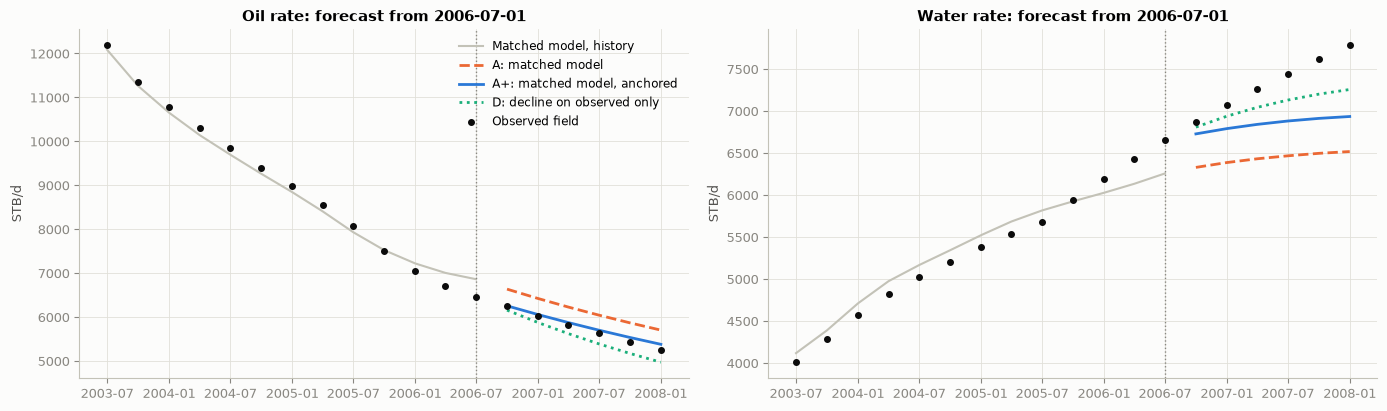

In [18]:
cut = dates.get_loc(pd.Timestamp('2006-07-01'))
h, bt_dates = slice(0, cut + 1), dates[cut + 1:]
o, oc = field['obs_rate'], field['obs_cum']
proxy_cut = CurveProxy().fit(params, field['rate'][:, h], field['cum'][:, h])
sel_cut, _ = history_match(Misfit(proxy_cut, o[h], oc[h]), box, n_sobol_log2=12, n_starts=10)
th_cut = sel_cut[PARAM_COLS].to_numpy()
fc_A = forecast(proxy_cut, th_cut, dates[h], o[h], oc[h], corr, fc_dates=bt_dates, anchor=False)
fc_Ap = forecast(proxy_cut, th_cut, dates[h], o[h], oc[h], corr, fc_dates=bt_dates, anchor=True)
r_D, _, _ = decline_forecast(o[None, h], oc[None, h], dates[h], bt_dates, 5, corr)

win = slice(cut - 12, None)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for ax, v in zip(axes, (0, 2)):
    ax.plot(dates[cut - 12:cut + 1], np.median(fc_A['rate_hist'][:, -13:, v], 0), color=C['provided'], lw=1.5,
            label='Matched model, history')
    for name, r, ls in [('A: matched model', fc_A['rate'], '--'), ('A+: matched model, anchored', fc_Ap['rate'], '-'),
                        ('D: decline on observed only', r_D, ':')]:
        ax.plot(bt_dates, np.median(r[:, :, v], 0), color=method_colors[name], ls=ls, label=name)
    ax.scatter(dates[win], o[win, v], s=16, color=C['actual'], zorder=3, label='Observed field')
    ax.axvline(dates[cut], color=C['muted'], lw=1, ls=':')
    ax.set_title(f'{VARS[v].title()} rate: forecast from 2006-07-01')
    ax.set_ylabel('STB/d')
axes[0].legend(loc='upper right', fontsize=8.5)
fig.tight_layout()
plt.show()

The unanchored model (A) starts the forecast from the model's own late-time rate, which is already off from the field,
and that error carries forward. Anchoring (A+) keeps the model's decline shape but removes the jump, so it has the
lowest oil error on average. **A+ is used for the deliverable.** Water is the harder phase for every method, so the
water forecast carries the most uncertainty.

## 10. Final forecast, 2008 → 2028

Forecast the 10 selected cases with A+ (and A, for comparison). The data contains **one real quarter beyond the
simulations**: the observed rate for 2008-01 → 2008-04. Neither the proxy nor the matcher has seen it, so it is a true
out-of-sample check of the first forecast step.

In [19]:
fc = forecast(proxy, theta, dates, field['obs_rate'], field['obs_cum'], corr, anchor=True)
fc_raw = forecast(proxy, theta, dates, field['obs_rate'], field['obs_cum'], corr, anchor=False)

oos = pd.DataFrame({
    'Observed 2008-01 → 2008-04': field['obs_next'][[0, 2]],
    'A+ anchored (median of 10)': np.median(fc['rate'][:, 0, [0, 2]], 0),
    'A unanchored (median of 10)': np.median(fc_raw['rate'][:, 0, [0, 2]], 0),
}, index=['Oil rate [STB/d]', 'Water rate [STB/d]'])
oos['A+ error %'] = 100 * (oos.iloc[:, 1] / oos.iloc[:, 0] - 1)
oos['A error %'] = 100 * (oos.iloc[:, 2] / oos.iloc[:, 0] - 1)
display(oos.round(1))

,Observed 2008-01 → 2008-04,A+ anchored (median of 10),A unanchored (median of 10),A+ error %,A error %
Oil rate [STB/d],5066.7,5131.6,5794.1,1.3,14.4
Water rate [STB/d],7926.4,7901.1,7134.3,-0.3,-10.0


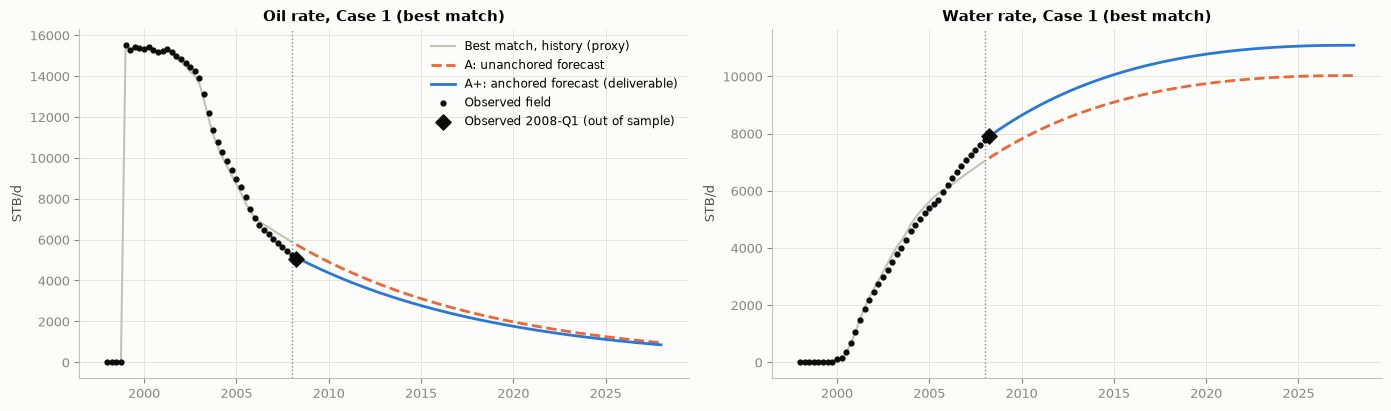

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for ax, v in zip(axes, (0, 2)):
    ax.plot(dates, fc['rate_hist'][0, :, v], color=C['provided'], lw=1.5, label='Best match, history (proxy)')
    ax.plot(FC_DATES, fc_raw['rate'][0, :, v], color=C['alt'], ls='--', label='A: unanchored forecast')
    ax.plot(FC_DATES, fc['rate'][0, :, v], color=C['matched'], label='A+: anchored forecast (deliverable)')
    ax.scatter(dates, field['obs_rate'][:, v], s=12, color=C['actual'], zorder=3, label='Observed field')
    ax.scatter([FC_DATES[0]], [field['obs_next'][v]], s=60, marker='D', color=C['actual'], zorder=4,
               label='Observed 2008-Q1 (out of sample)')
    ax.axvline(dates[-1], color=C['muted'], lw=1, ls=':')
    ax.set_title(f'{VARS[v].title()} rate, Case 1 (best match)')
    ax.set_ylabel('STB/d')
    ax.xaxis.set_major_locator(mdates.YearLocator(5))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
axes[0].legend(loc='upper right', fontsize=8.5)
fig.tight_layout()
plt.show()

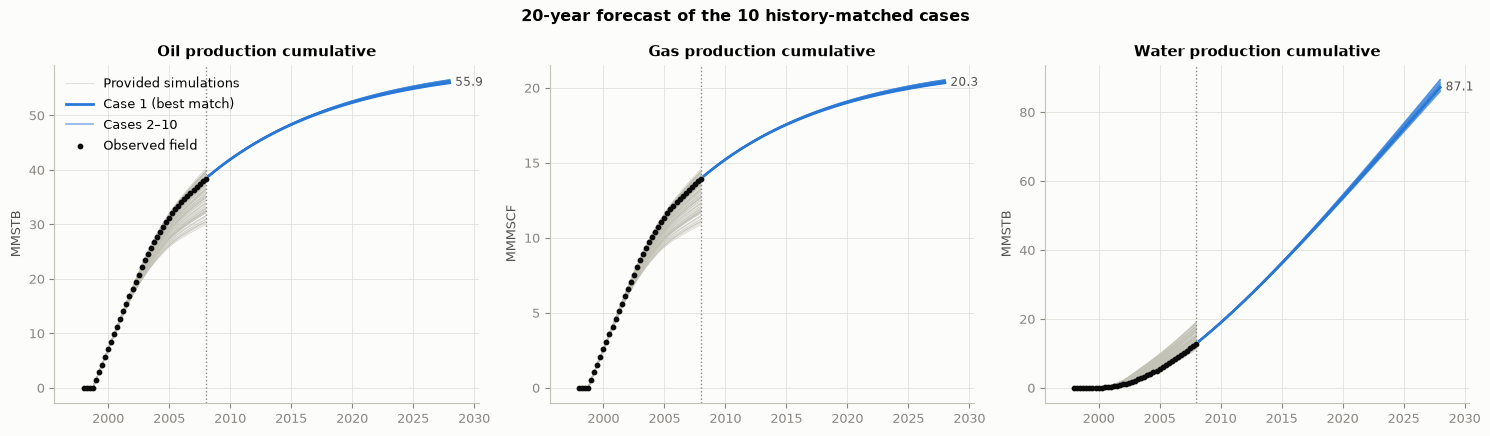

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
for ax, v in zip(axes, [0, 1, 2]):
    for j, curve in enumerate(field['cum'][:, :, v]):
        ax.plot(dates, curve / 1e6, color=C['provided'], lw=0.6, alpha=0.6,
                label='Provided simulations' if j == 0 else None)
    for j, curve in enumerate(fc['cum'][:, :, v]):
        ax.plot(FC_DATES, curve / 1e6, color=C['matched'], lw=1.2 if j else 2, alpha=0.55 if j else 1,
                label='Case 1 (best match)' if j == 0 else ('Cases 2–10' if j == 1 else None))
    ax.scatter(dates, field['obs_cum'][:, v] / 1e6, s=10, color=C['actual'], zorder=3, label='Observed field')
    ax.axvline(dates[-1], color=C['muted'], lw=1, ls=':')
    ax.annotate(f'{fc["cum"][0, -1, v] / 1e6:.1f}', (FC_DATES[-1], fc['cum'][0, -1, v] / 1e6), xytext=(4, 0),
                textcoords='offset points', va='center', fontsize=8.5, color='#52514e')
    ax.set_title(f'{VARS[v].title()} production cumulative')
    ax.set_ylabel(f'MM{UNITS[v]}')
    ax.xaxis.set_major_locator(mdates.YearLocator(5))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    ax.margins(x=0.08)
axes[0].legend(loc='upper left')
fig.suptitle('20-year forecast of the 10 history-matched cases', fontweight='bold')
fig.tight_layout()
plt.show()

In [22]:
summary = selected.copy()
for v, (name, unit) in enumerate(zip(VARS, UNITS)):
    summary[f'{name} cum 2028 [MM{unit}]'] = fc['cum'][:, -1, v] / 1e6
    summary[f'{name} added 2008→2028 [MM{unit}]'] = (fc['cum'][:, -1, v] - field['obs_cum'][-1, v]) / 1e6
display(summary.round(3))

cols = [c for c in summary.columns if 'cum 2028' in c]
display(summary[cols].quantile([0.1, 0.5, 0.9]).rename(index={0.1: 'P10', 0.5: 'P50', 0.9: 'P90'}).round(2))

,misfit,Fault Transmissibility,Porosity Multiplier,Permeability Multiplier,Aquifer Pore Volume,oil cum 2028 [MMSTB],oil added 2008→2028 [MMSTB],gas cum 2028 [MMMSCF],gas added 2008→2028 [MMMSCF],water cum 2028 [MMSTB],water added 2008→2028 [MMSTB]
Case 1,0.442,0.096,1.383,0.944,182.252,55.947,17.568,20.323,6.381,87.116,74.302
Case 2,0.448,0.143,1.384,0.564,164.418,55.926,17.548,20.316,6.373,85.912,73.098
Case 3,0.461,0.116,1.368,3.113,189.173,56.234,17.855,20.428,6.485,88.635,75.821
Case 4,0.462,0.052,1.364,1.453,142.301,56.009,17.631,20.346,6.404,87.638,74.823
Case 5,0.465,0.148,1.365,2.114,125.602,56.228,17.850,20.426,6.483,88.274,75.460
Case 6,0.469,0.058,1.402,0.665,195.953,56.031,17.653,20.354,6.412,86.829,74.015
Case 7,0.473,0.104,1.349,3.027,115.620,56.475,18.096,20.515,6.573,87.986,75.171
Case 8,0.475,0.053,1.362,4.559,193.433,56.438,18.060,20.502,6.559,89.287,76.472
Case 9,0.485,0.093,1.371,0.784,104.771,56.179,17.801,20.408,6.465,86.250,73.435
Case 10,0.485,0.062,1.344,4.703,95.341,56.436,18.057,20.501,6.558,89.288,76.473


,oil cum 2028 [MMSTB],gas cum 2028 [MMMSCF],water cum 2028 [MMSTB]
P10,55.94,20.32,86.22
P50,56.20,20.42,87.81
P90,56.44,20.50,89.29


## 11. Write the deliverable

Fill the **official** template (`dwc26/TestCases/09 Template Deliverable.xlsx`; the copy in the repo root has a
truncated `Case 1` sheet) and save it as `outputs/09 Template Deliverable.xlsx`. Only the value cells are written,
so the dates and formatting stay exactly as the organisers made them. Sheet `Case k` = the k-th selected case.

In [23]:
write_template(fc['cum'], TEMPLATE_PATH, DELIVERABLE_PATH)

out = pd.read_excel(DELIVERABLE_PATH, sheet_name=None)
tmpl = pd.read_excel(TEMPLATE_PATH, sheet_name=None)
assert list(out) == list(tmpl) and all(out[k].shape == tmpl[k].shape for k in out)
assert all(out[k]['Date'].astype(str).equals(tmpl[k]['Date'].astype(str)) for k in out)
assert not any(df.isna().any().any() for df in out.values())
assert all((np.diff(df.iloc[:, 1:].to_numpy(), axis=0) >= 0).all() for df in out.values())
print(f'Wrote {DELIVERABLE_PATH.relative_to(ROOT)}: {len(out)} sheets × {len(out["Case 1"])} quarters, '
      'same dates as the template, no blanks, cumulatives never decrease')
display(out['Case 1'].head())

Wrote outputs\09 Template Deliverable.xlsx: 10 sheets × 80 quarters, same dates as the template, no blanks, cumulatives never decrease


,Date,Gas production cumulative [MSCF],Oil production cumulative [STB],Water production cumulative [STB]
0,04/01/2008,1.411326e+07,3.884835e+07,1.353046e+07
1,07/01/2008,1.428015e+07,3.930785e+07,1.425680e+07
2,10/01/2008,1.444505e+07,3.976186e+07,1.500137e+07
3,01/01/2009,1.460621e+07,4.020557e+07,1.575592e+07
4,04/01/2009,1.476036e+07,4.063001e+07,1.650332e+07


## 12. Summary

**What was done**
- **History matching**, the missing step: the proxy is searched over the full parameter range for the parameter sets
  that best reproduce the observed field. The best match (misfit ≈ 0.44) beats every provided simulation (best: case 76,
  ≈ 0.45).
- **10 cases** were chosen among all acceptable matches so that they differ as much as possible, ranked by misfit.
- **20-year forecast** with the matched model's decline shape, anchored to the field's last observed rates and
  cumulatives. It is written into the official template.

**Evidence it works**
- Proxy on unseen cases: < 0.1 % error on 2008 cumulatives.
- Blind test: porosity recovered within ~1 % of its range; 2028 forecasts within ~0.5 % of the truth on average.
- Field backtest: the anchored forecast has the lowest oil error (about 2 % on average).
- Real 2008-Q1 quarter (out of sample): oil +1.3 %, water −0.3 % (unanchored: +14 % / −10 %).

**Key findings**
- **Porosity drives everything** and the history pins it at ~1.38. Fault transmissibility is barely constrained and
  barely matters.
- **The field produces more water late in life than any provided simulation.** Without anchoring, the forecast would
  start ~14 % too high on oil.
- By 2028 the field reaches about **56 MMSTB oil, 20 MMMSCF gas and 87 MMSTB water** (see the P10/P50/P90 table).

**Caveats for the presentation**
- There is no data after 2008. The backtests only reach 3 years ahead; the forecast runs 20.
- The spread between the 10 cases reflects *parameter* uncertainty only. The larger uncertainty is the model itself
  (the water-cut gap) and the future well-control schedule.
- Water is the least certain phase: the backtests' water errors are the largest, and the GRU in
  `ML_Proxy_Model.ipynb` gave a much lower water forecast than the decline methods.